In [1]:
import os,sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from pathlib import Path 

# Load Datasets
url_reviews = "https://mydataaijournal.com/public/andy-data/olist-data/raw_data/olist_order_reviews_dataset.csv"


df_reviews_raw = pd.read_csv(url_reviews)
print(f"Successfully loaded {len(df_reviews_raw):,} reviews!")

df_reviews = df_reviews_raw.copy()

# HOME_PATH = Path.home()
# #print(f"path: {HOME_PATH}")
# LIB_PATH = HOME_PATH / "Documents" / "___andy_lib"
# sys.path.append(str(LIB_PATH))
# from clean import clean_lib #type:ignore

# #clean_lib.null_data(df_orders)


Successfully loaded 99,224 reviews!


In [2]:
df_reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [3]:
df_reviews["review_creation_date"] = (
    pd.to_datetime(df_reviews["review_creation_date"],errors="coerce")
)
min_date = df_reviews["review_creation_date"].min()
max_date = df_reviews["review_creation_date"].max()
total_days = (max_date - min_date).days

print(f"minimum date: {min_date}")
print(f"maximum date: {max_date}")
print(f"total days: {total_days}")

# df_reviews.info()

minimum date: 2016-10-02 00:00:00
maximum date: 2018-08-31 00:00:00
total days: 698


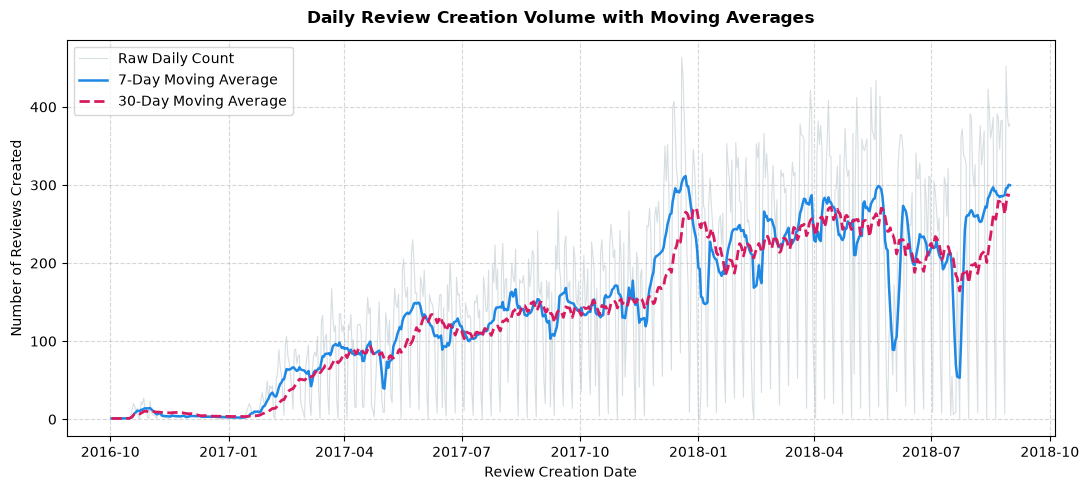

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Ensure review_creation_date is parsed as datetime
df_reviews["review_creation_date"] = pd.to_datetime(
    df_reviews["review_creation_date"], errors="coerce"
)

# 2. Group by date to get daily review counts
daily_reviews = (
    df_reviews.groupby(df_reviews["review_creation_date"].dt.date)
    .size()
    .reset_index(name="review_count")
)

# Convert the grouped date column back to datetime for smooth plotting
daily_reviews["review_creation_date"] = pd.to_datetime(
    daily_reviews["review_creation_date"]
)

# 3. Calculate Moving Averages
daily_reviews["ma_7"] = (
    daily_reviews["review_count"].rolling(window=7, min_periods=1).mean()
)
daily_reviews["ma_30"] = (
    daily_reviews["review_count"].rolling(window=30, min_periods=1).mean()
)

# 4. Plot
plt.figure(figsize=(11, 5))
plt.plot(
    daily_reviews["review_creation_date"],
    daily_reviews["review_count"],
    color="#b0bec5",
    alpha=0.5,
    linewidth=0.8,
    label="Raw Daily Count",
)
plt.plot(
    daily_reviews["review_creation_date"],
    daily_reviews["ma_7"],
    color="#1e88e5",
    linewidth=1.8,
    label="7-Day Moving Average",
)
plt.plot(
    daily_reviews["review_creation_date"],
    daily_reviews["ma_30"],
    color="#d81b60",
    linewidth=2.0,
    linestyle="--",
    label="30-Day Moving Average",
)

plt.title(
    "Daily Review Creation Volume with Moving Averages",
    fontsize=12,
    fontweight="bold",
    pad=12,
)
plt.xlabel("Review Creation Date", fontsize=10)
plt.ylabel("Number of Reviews Created", fontsize=10)
plt.legend(loc="upper left", frameon=True)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.show()

<div style="width:90%;margin:auto;font-size:1.2em;">

## Summary of `df_reviews` Dataset

### 1. Dataset Overview
* **Total Observations:** 99,224 review records.
* **Date Range:** Covers **698 days** (~1.9 years) from **October 02, 2016** to **August 31, 2018**.
* **Memory Usage:** ~5.3 MB.

</div>



In [5]:
selected_cols = [
    "review_id",
    "order_id",
    "review_score",
]

df_reviews = df_reviews[selected_cols]

df_reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   review_id     99224 non-null  object
 1   order_id      99224 non-null  object
 2   review_score  99224 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 2.3+ MB


In [6]:
reviews_breakdown = df_reviews.review_score.value_counts(dropna=False).sort_index()

reviews_breakdown

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

In [8]:
reviews_breakdown = reviews_breakdown.reset_index()
# 1. Define Bad Reviews & Calculate Proportions
reviews_breakdown['is_bad_review'] = np.where(reviews_breakdown['review_score'] <= 3, 1, 0)

# Aggregate counts and percentage shares
summary = (
    reviews_breakdown.groupby("is_bad_review", as_index=False)
    .agg(total_reviews=('count', 'sum'))
)

display(reviews_breakdown)

display(summary)

,review_score,count,is_bad_review
0,1,11424,1
1,2,3151,1
2,3,8179,1
3,4,19142,0
4,5,57328,0


,is_bad_review,total_reviews
0,0,76470
1,1,22754
